In [1]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load MNIST and scale images to [-1, 1]
(X_train, _), _ = tf.keras.datasets.mnist.load_data()
X_train = np.expand_dims(X_train.astype("float32") / 127.5 - 1, -1)

# Set noise size and image shape
latent_dim = 100
img_shape = X_train.shape[1:]

In [3]:
# Create Generator
def build_generator():
    return tf.keras.Sequential([
        layers.Input((latent_dim,)),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(256, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(512, activation="relu"),
        layers.BatchNormalization(),
        layers.Dense(int(np.prod(img_shape)), activation="tanh"),
        layers.Reshape(img_shape)
    ])

# Create Discriminator
def build_discriminator():
    return tf.keras.Sequential([
        layers.Input(img_shape),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

generator = build_generator()
discriminator = build_discriminator()

In [4]:
# Optimisers
opt_d = tf.keras.optimizers.Adam(0.0002, 0.5)
opt_g = tf.keras.optimizers.Adam(0.0002, 0.5)

# Compile Discriminator
discriminator.compile(optimizer=opt_d, loss="binary_crossentropy", metrics=["accuracy"])
discriminator.trainable = False

# Create GAN
gan_input = layers.Input((latent_dim,))
gan = tf.keras.Model(gan_input, discriminator(generator(gan_input)))
gan.compile(optimizer=opt_g, loss="binary_crossentropy")

In [5]:
# Generate, save and display sample images
def save_generated_images(epoch, examples=25):
    imgs = 0.5 * generator.predict(np.random.normal(0,1,(examples,latent_dim)), verbose=0) + 0.5
    plt.figure(figsize=(10,10))
    for i in range(examples):
        plt.subplot(5,5,i+1)
        plt.imshow(imgs[i,:,:,0], cmap="gray")
        plt.axis("off")
    plt.tight_layout()
    plt.savefig(f"generated_{epoch}.png")
    plt.show()
    plt.close()

In [6]:
# Train GAN
def train_gan(epochs=500, batch_size=64, save_interval=100):
    # Labels for real and fake images
    valid = np.ones((batch_size,1), dtype="float32")
    fake = np.zeros((batch_size,1), dtype="float32")

    for epoch in range(epochs):
        # Sample real images and generate fake images
        idx = np.random.randint(0, len(X_train), batch_size)
        real_imgs = X_train[idx]
        noise = np.random.normal(0,1,(batch_size,latent_dim))
        fake_imgs = generator.predict(noise, verbose=0)

        # Train Discriminator
        discriminator.trainable = True
        d_real = discriminator.train_on_batch(real_imgs, valid)
        d_fake = discriminator.train_on_batch(fake_imgs, fake)
        d_loss = 0.5 * (np.array(d_real) + np.array(d_fake))

        # Train Generator
        discriminator.trainable = False
        g_loss = gan.train_on_batch(np.random.normal(0,1,(batch_size,latent_dim)), valid)

        print(f"{epoch+1}/{epochs} [D loss: {d_loss[0]:.4f} | D acc: {100*d_loss[1]:.2f}%] [G loss: {float(np.asarray(g_loss)):.4f}]")

        # Save sample images
        if (epoch+1) % save_interval == 0:
            save_generated_images(epoch+1)

1/500 [D loss: 0.7523 | D acc: 52.34%] [G loss: 0.7627]
2/500 [D loss: 0.3715 | D acc: 100.00%] [G loss: 0.7627]
3/500 [D loss: 0.2908 | D acc: 100.00%] [G loss: 0.7607]
4/500 [D loss: 0.2344 | D acc: 100.00%] [G loss: 0.8254]
5/500 [D loss: 0.2095 | D acc: 100.00%] [G loss: 0.9079]
6/500 [D loss: 0.1776 | D acc: 100.00%] [G loss: 0.9262]
7/500 [D loss: 0.1578 | D acc: 100.00%] [G loss: 1.0104]
8/500 [D loss: 0.1342 | D acc: 100.00%] [G loss: 1.0425]
9/500 [D loss: 0.1090 | D acc: 100.00%] [G loss: 1.1082]
10/500 [D loss: 0.1057 | D acc: 100.00%] [G loss: 1.0918]
11/500 [D loss: 0.0950 | D acc: 100.00%] [G loss: 1.2050]
12/500 [D loss: 0.0903 | D acc: 100.00%] [G loss: 1.2181]
13/500 [D loss: 0.0830 | D acc: 100.00%] [G loss: 1.2543]
14/500 [D loss: 0.0806 | D acc: 100.00%] [G loss: 1.3205]
15/500 [D loss: 0.0729 | D acc: 100.00%] [G loss: 1.3384]
16/500 [D loss: 0.0723 | D acc: 100.00%] [G loss: 1.4246]
17/500 [D loss: 0.0645 | D acc: 100.00%] [G loss: 1.5586]
18/500 [D loss: 0.0621 |

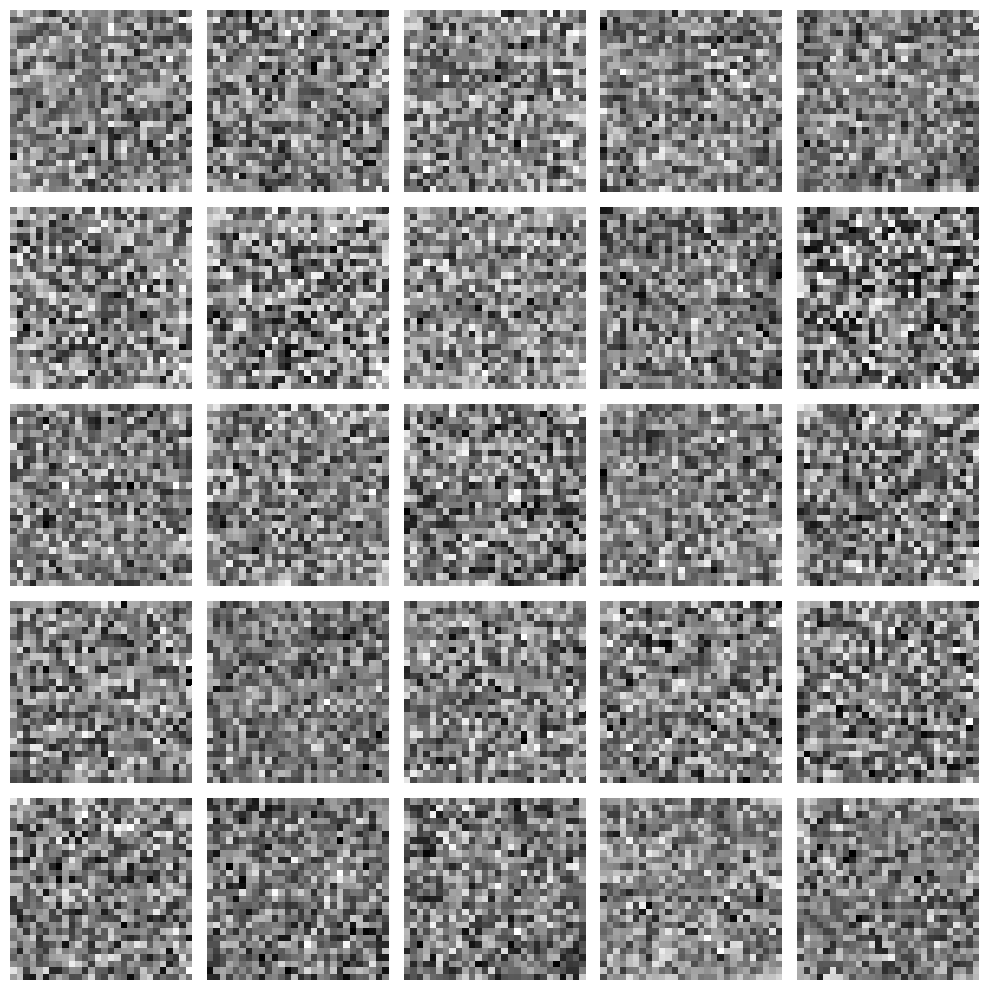

101/500 [D loss: 0.0071 | D acc: 100.00%] [G loss: 6.5185]
102/500 [D loss: 0.0094 | D acc: 100.00%] [G loss: 6.4588]
103/500 [D loss: 0.0090 | D acc: 100.00%] [G loss: 6.4747]
104/500 [D loss: 0.0080 | D acc: 100.00%] [G loss: 6.7748]
105/500 [D loss: 0.0095 | D acc: 100.00%] [G loss: 6.5897]
106/500 [D loss: 0.0089 | D acc: 100.00%] [G loss: 6.4507]
107/500 [D loss: 0.0103 | D acc: 100.00%] [G loss: 6.7879]
108/500 [D loss: 0.0050 | D acc: 100.00%] [G loss: 6.7413]
109/500 [D loss: 0.0079 | D acc: 100.00%] [G loss: 6.8683]
110/500 [D loss: 0.0059 | D acc: 100.00%] [G loss: 6.9030]
111/500 [D loss: 0.0116 | D acc: 100.00%] [G loss: 7.0102]
112/500 [D loss: 0.0088 | D acc: 100.00%] [G loss: 6.9048]
113/500 [D loss: 0.0096 | D acc: 100.00%] [G loss: 6.8641]
114/500 [D loss: 0.0114 | D acc: 100.00%] [G loss: 6.6061]
115/500 [D loss: 0.0086 | D acc: 100.00%] [G loss: 6.8682]
116/500 [D loss: 0.0116 | D acc: 100.00%] [G loss: 7.3468]
117/500 [D loss: 0.0079 | D acc: 100.00%] [G loss: 6.979

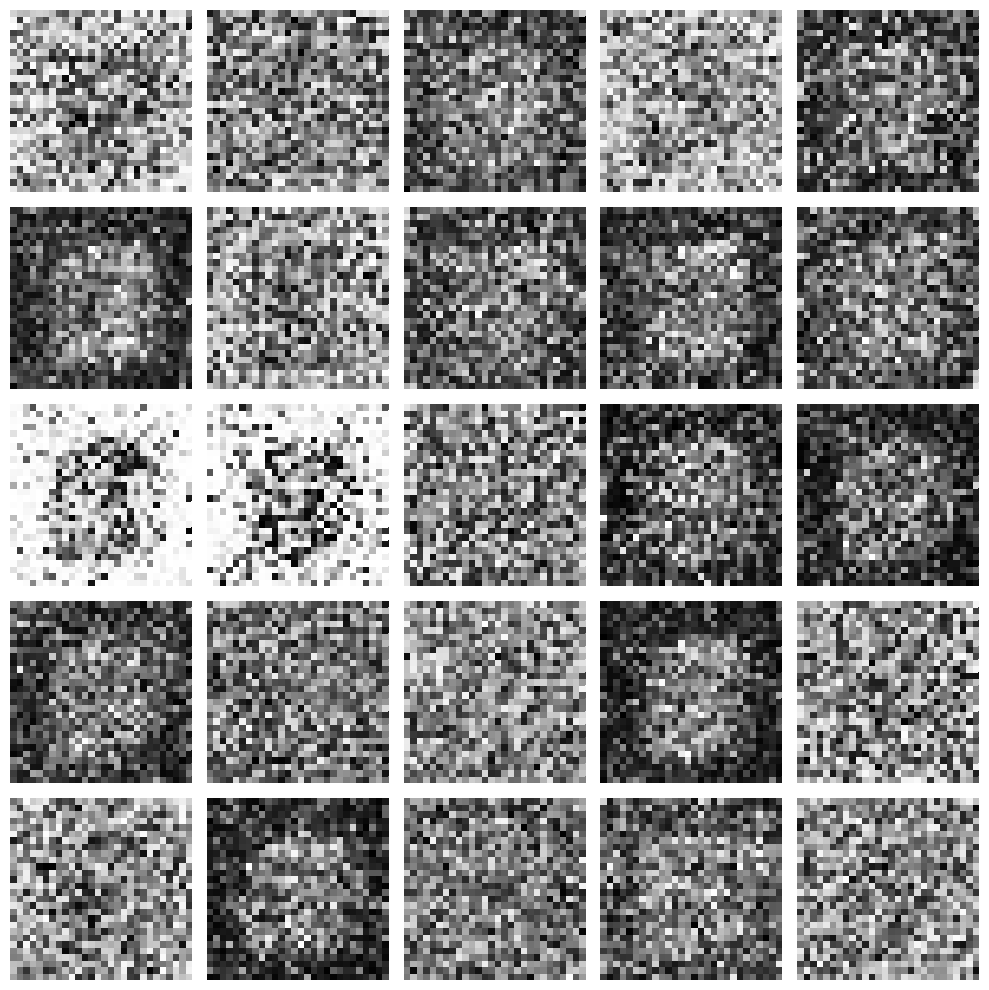

201/500 [D loss: 0.2067 | D acc: 90.62%] [G loss: 7.1359]
202/500 [D loss: 0.8153 | D acc: 67.97%] [G loss: 5.5701]
203/500 [D loss: 0.6345 | D acc: 81.25%] [G loss: 5.6099]
204/500 [D loss: 0.2387 | D acc: 87.50%] [G loss: 6.2733]
205/500 [D loss: 0.0683 | D acc: 98.44%] [G loss: 6.8607]
206/500 [D loss: 0.3057 | D acc: 85.16%] [G loss: 5.5897]
207/500 [D loss: 0.1620 | D acc: 90.62%] [G loss: 5.6562]
208/500 [D loss: 0.1669 | D acc: 89.84%] [G loss: 5.8981]
209/500 [D loss: 0.1021 | D acc: 96.09%] [G loss: 5.9613]
210/500 [D loss: 0.1557 | D acc: 92.97%] [G loss: 6.1798]
211/500 [D loss: 0.1607 | D acc: 92.19%] [G loss: 5.5862]
212/500 [D loss: 0.1721 | D acc: 91.41%] [G loss: 6.0183]
213/500 [D loss: 0.3853 | D acc: 82.81%] [G loss: 5.1138]
214/500 [D loss: 0.2211 | D acc: 89.06%] [G loss: 5.3933]
215/500 [D loss: 0.1110 | D acc: 96.09%] [G loss: 5.9220]
216/500 [D loss: 0.2846 | D acc: 84.38%] [G loss: 5.3499]
217/500 [D loss: 0.1128 | D acc: 94.53%] [G loss: 5.6286]
218/500 [D los

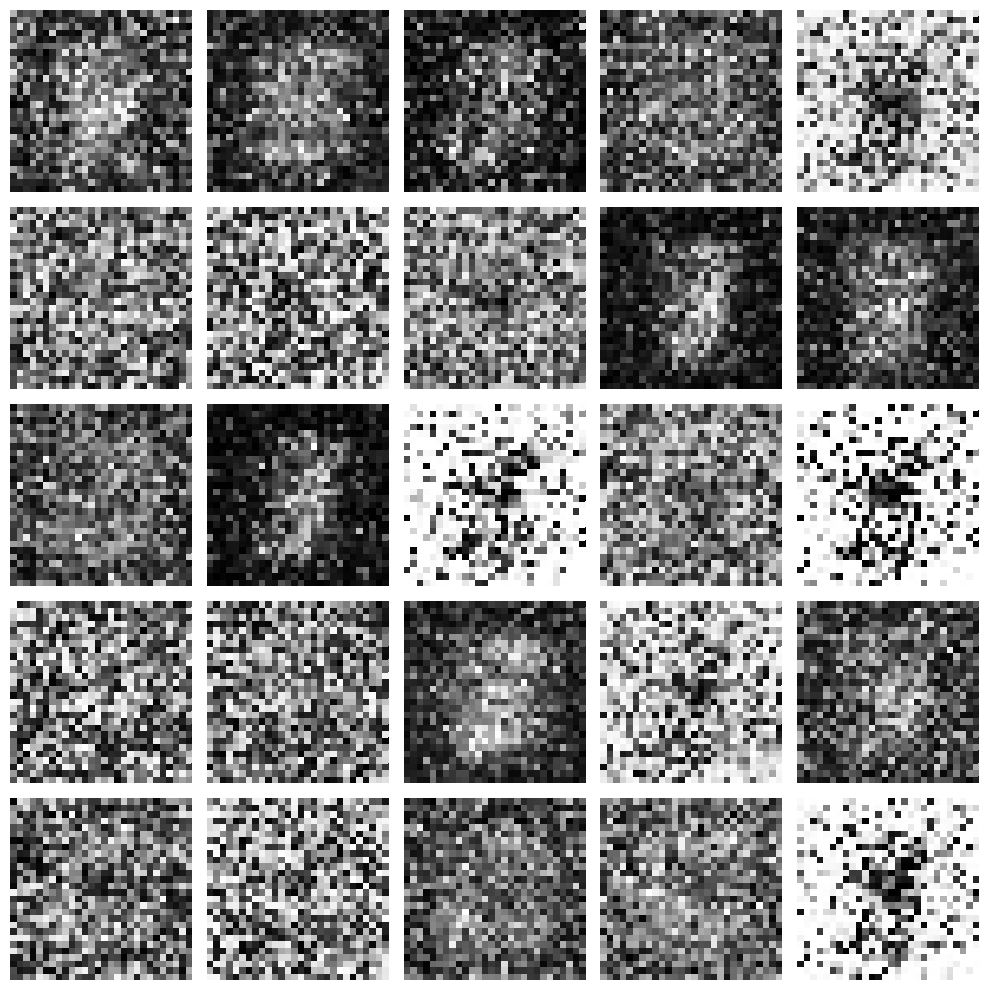

301/500 [D loss: 0.2148 | D acc: 85.94%] [G loss: 3.4363]
302/500 [D loss: 0.1618 | D acc: 94.53%] [G loss: 3.8716]
303/500 [D loss: 0.3665 | D acc: 80.47%] [G loss: 3.0367]
304/500 [D loss: 0.1764 | D acc: 91.41%] [G loss: 3.3637]
305/500 [D loss: 0.2745 | D acc: 87.50%] [G loss: 3.3581]
306/500 [D loss: 0.2381 | D acc: 89.84%] [G loss: 3.3648]
307/500 [D loss: 0.4203 | D acc: 74.22%] [G loss: 3.1810]
308/500 [D loss: 0.1704 | D acc: 92.19%] [G loss: 3.6891]
309/500 [D loss: 0.3675 | D acc: 80.47%] [G loss: 3.1987]
310/500 [D loss: 0.2128 | D acc: 89.84%] [G loss: 3.5894]
311/500 [D loss: 0.2832 | D acc: 86.72%] [G loss: 3.4828]
312/500 [D loss: 0.2041 | D acc: 93.75%] [G loss: 3.5134]
313/500 [D loss: 0.2540 | D acc: 90.62%] [G loss: 3.1110]
314/500 [D loss: 0.2055 | D acc: 86.72%] [G loss: 3.2794]
315/500 [D loss: 0.2531 | D acc: 89.84%] [G loss: 3.2581]
316/500 [D loss: 0.2610 | D acc: 87.50%] [G loss: 3.4376]
317/500 [D loss: 0.1971 | D acc: 92.19%] [G loss: 3.2673]
318/500 [D los

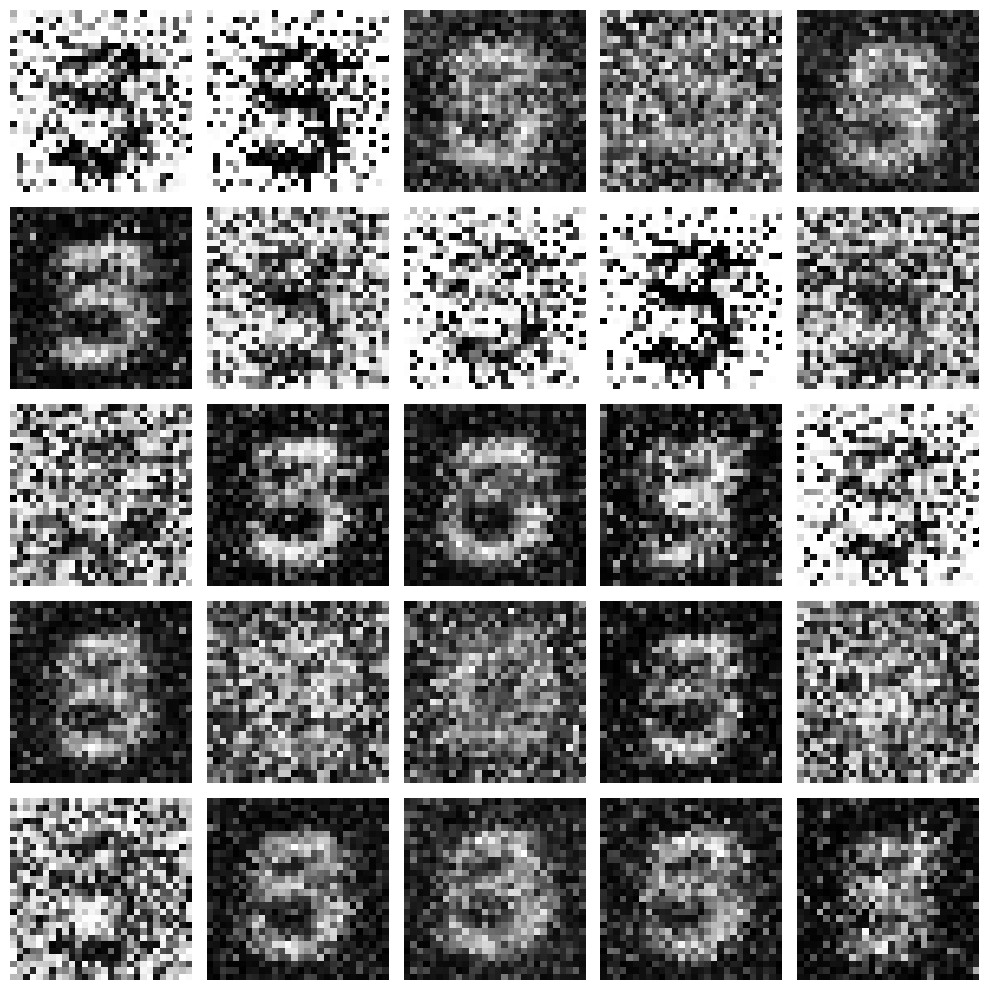

401/500 [D loss: 0.3122 | D acc: 85.16%] [G loss: 3.2510]
402/500 [D loss: 0.1582 | D acc: 92.19%] [G loss: 3.9096]
403/500 [D loss: 0.2939 | D acc: 89.06%] [G loss: 3.5275]
404/500 [D loss: 0.1300 | D acc: 95.31%] [G loss: 3.6836]
405/500 [D loss: 0.2812 | D acc: 84.38%] [G loss: 3.1595]
406/500 [D loss: 0.1395 | D acc: 94.53%] [G loss: 3.9941]
407/500 [D loss: 0.1948 | D acc: 93.75%] [G loss: 3.4209]
408/500 [D loss: 0.1610 | D acc: 94.53%] [G loss: 3.9713]
409/500 [D loss: 0.3430 | D acc: 85.94%] [G loss: 3.3234]
410/500 [D loss: 0.2154 | D acc: 89.84%] [G loss: 3.8819]
411/500 [D loss: 0.3809 | D acc: 81.25%] [G loss: 3.0642]
412/500 [D loss: 0.1647 | D acc: 92.19%] [G loss: 3.4092]
413/500 [D loss: 0.2584 | D acc: 89.84%] [G loss: 3.5312]
414/500 [D loss: 0.2343 | D acc: 90.62%] [G loss: 3.7983]
415/500 [D loss: 0.3267 | D acc: 82.03%] [G loss: 3.5889]
416/500 [D loss: 0.1260 | D acc: 97.66%] [G loss: 3.3753]
417/500 [D loss: 0.3148 | D acc: 82.81%] [G loss: 3.3717]
418/500 [D los

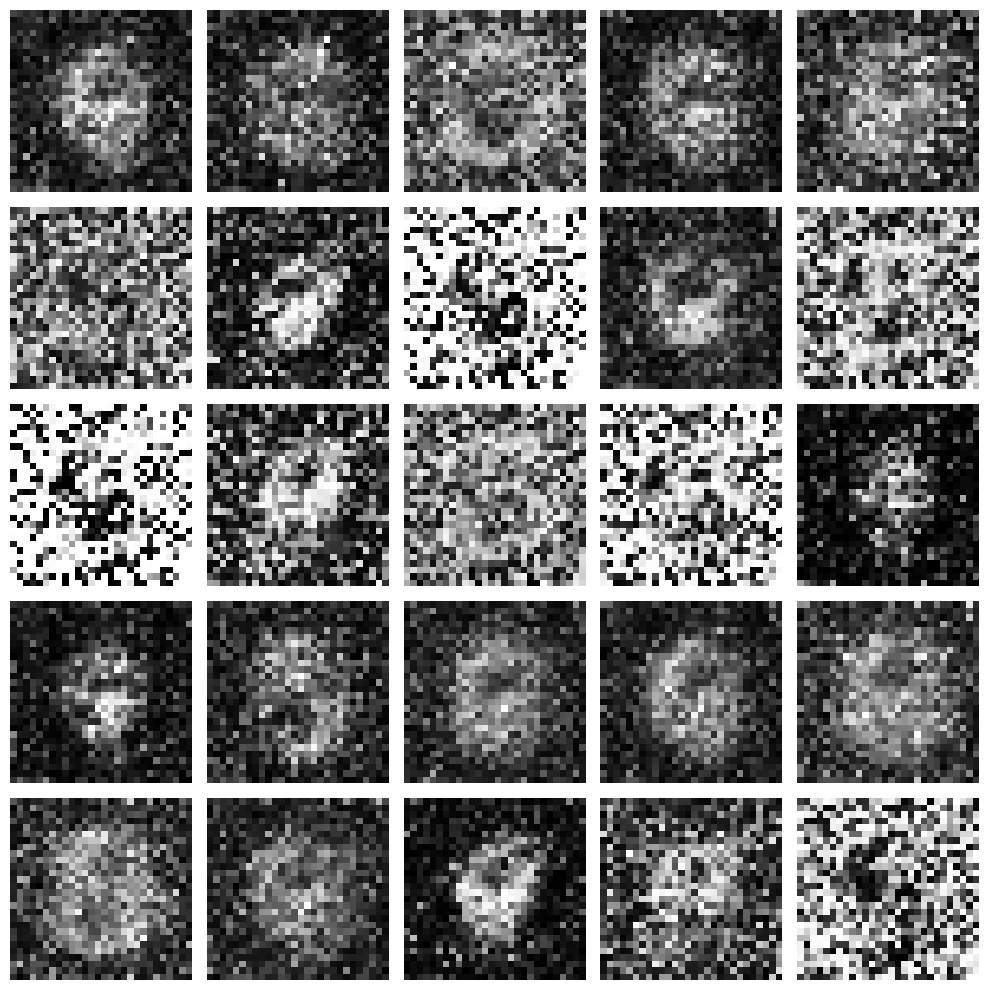

In [7]:
# Start training
train_gan()